Step 1: Split the received signal as ref signal \& loc signal. Get the basic information including sample rate, starting time, etc, and save it to folder with name $date/

In [2]:
from utils.calibration import CalibrationSignal
import os
from matplotlib import pyplot as plt
import scipy.io as sio
import numpy as np
# iq0_path ='/home/ishani/LeoPNT/USRP_data/2_5/utctime_5Feb2024_23:58:08_freq_11_325G_bw_2.0M_ts_1707177488.0938272_inrx0.dat'
iq0_path ='/home/ishani/LeoPNT/USRP_data/2_20/utctime_20Feb2024_23_19_57_freq_11_325G_bw_2.0M_ts_1708471197.0514207_inrx0.dat'
iq1_path = iq0_path.replace('inrx0', 'inrx1')
iq2_path = iq0_path.replace('inrx0', 'inrx2')
# date = iq0_path.split('_')[-10]+'_'+iq0_path.split('_')[-9].replace(":","-")
date = iq0_path.split('_')[-12]+'_'+iq0_path.split('_')[-11]+'_'+iq0_path.split('_')[-10]
start_time = float(iq0_path.split('_')[-2])
fc = 11.325e9
tx_freq = 11.3251e9
sample_rate = 2e6
# cal0 = CalibrationSignal(iq0_path, fc, tx_freq, sample_rate) # creates an instance of CalibrationSignal. More details in utils/calibration.py 
# cal1 = CalibrationSignal(iq1_path, fc, tx_freq, sample_rate)
# cal2 = CalibrationSignal(iq2_path, fc, tx_freq, sample_rate)
# ref_sig_idx = cal0.get_all_refsigidx() # use the get_all_refsigidx() method to get the start and stop index of the reference signal
# phase_0 = cal0.get_refsig_phase(ref_sig_idx)
# phase_1 = cal1.get_refsig_phase(ref_sig_idx)
# phase_2 = cal2.get_refsig_phase(ref_sig_idx)

# t_end = ref_sig_idx[-1][1]/sample_rate  # use the stop time of the last ref sig as the duration of the file
# phase_offset_01 = np.unwrap(phase_0-phase_1)
# phase_offset_21 = np.unwrap(phase_2-phase_1)

# if not os.path.exists(date):
#     os.makedirs(date)
# # save sample_rate, date, start_time, loc_sig_idx to .mat file
# sio.savemat(date + '/info.mat', {'IQ_Sample_file_0': iq0_path,'sample_rate': sample_rate, 'date': date, 'start_time': start_time, 'ref_sig_idx': ref_sig_idx, 't_end': t_end, 'phase_offset_01': phase_offset_01, 'phase_offset_21': phase_offset_21})
# plt.plot(phase_offset_01, label='rx0    -    rx1')
# plt.plot(phase_offset_21, label='rx2    -    rx1')
# plt.xlabel('ref sig #')
# plt.legend(loc='upper right')
# plt.show()


Step 2: do the central tone tracking using matlab

In [1]:
# need to change date first in matlab file
# matlab
# cd Starloc/
# phase_from_bin_track
# results saved to $date/res.mat

Step 3: have a look at the results

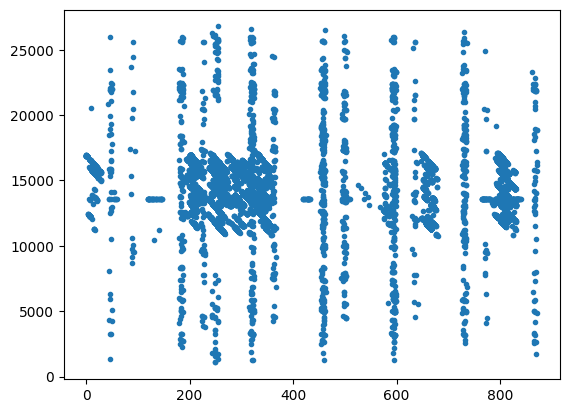

In [13]:
from matplotlib import pyplot as plt
from scipy import io as sio
res = sio.loadmat(date + '/res.mat')['res']
plt.close('all')
# %matplotlib widget
plt.plot(res[:, 0], res[:, 1], '.')
plt.show()

Step 4: simulate doppler, first need to move the tle file to the date folder with name `Starlink.tle`

In [10]:
from sat_id import connect_doppler, doppler_sim
sim_start_time = start_time
t_end = sio.loadmat(date + '/info.mat')['t_end'][0][0]
sim_end_time = sim_start_time+t_end
sat_dopp_dict, t_list = doppler_sim(date, date+'/Starlink.tle', fc, sim_start_time, sim_end_time, 1)
output_doppler_file = date+"/output_doppler.mat"
output = {}
sio.savemat(output_doppler_file, {'sat_dopp_dict': sat_dopp_dict, 't_list': t_list})

number of Starlink satellites loaded 5448
1 STARLINK-1007


2 STARLINK-1008
3 STARLINK-1009
4 STARLINK-1010
5 STARLINK-1011
6 STARLINK-1012
7 STARLINK-1013
8 STARLINK-1014
9 STARLINK-1015
10 STARLINK-1017
11 STARLINK-1019
12 STARLINK-1020
13 STARLINK-1021
14 STARLINK-1024
15 STARLINK-1027
16 STARLINK-1028
17 STARLINK-1029
18 STARLINK-1030
19 STARLINK-1031
20 STARLINK-1032
21 STARLINK-1035
22 STARLINK-1036
23 STARLINK-1038
24 STARLINK-1039
25 STARLINK-1041
26 STARLINK-1042
27 STARLINK-1043
28 STARLINK-1046
29 STARLINK-1047
30 STARLINK-1048
31 STARLINK-1052
32 STARLINK-1053
33 STARLINK-1054
34 STARLINK-1055
35 STARLINK-1056
36 STARLINK-1057
37 STARLINK-1058
38 STARLINK-1059
39 STARLINK-1060
40 STARLINK-1061
41 STARLINK-1062
42 STARLINK-1063
43 STARLINK-1067
44 STARLINK-1068
45 STARLINK-1073
46 STARLINK-1084
47 STARLINK-1098
48 STARLINK-1099
49 STARLINK-1102
50 STARLINK-1103
51 STARLINK-1104
52 STARLINK-1106
53 STARLINK-1111
54 STARLINK-1112
55 STARLINK-1113
56 STARLINK-1114
57 STARLINK-1119
58 STARLINK-1121
59 STARLINK-1123
60 STARLINK-1128
61 ST

Step 5: Run `phase_from_bin.m` to get phase difference.

Step 6: Do localization based on phase diff

/home/jidazhang/anaconda3/envs/starloc/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/jidazhang/anaconda3/envs/starloc/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


/home/jidazhang/anaconda3/envs/starloc/lib/python3.9/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/jidazhang/anaconda3/envs/starloc/lib/python3.9/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


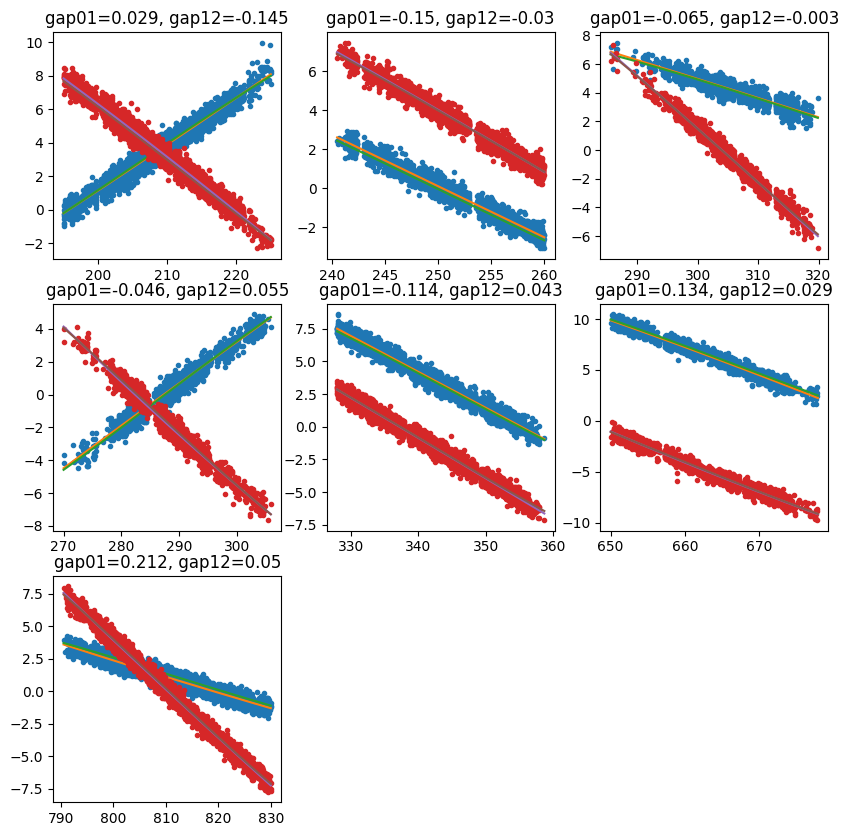

In [25]:
# first cheat by using the gt location to get the random phase offset (mean value for all satellites)
from sat_id import aoa_sim_1_sat, aoa_sim_1_sat_eph
t_sim_list = sio.loadmat(date+'/output_doppler.mat')['t_list']
dopp_track_dict = sio.loadmat(date+'/phase_comp.mat')['dopp_track_dict']
id_dict = sio.loadmat(date+'/phase_comp.mat')['id_dict']
sat_dopp_struct = sio.loadmat(date+'/phase_comp.mat')['sat_dopp_dict']
ref_sig_idx = sio.loadmat(date+'/info.mat')['ref_sig_idx']
phase_offset_01 = sio.loadmat(date+'/info.mat')['phase_offset_01'][0]
phase_offset_21 = sio.loadmat(date+'/info.mat')['phase_offset_21'][0]
sat_num = len(dopp_track_dict[0, :])

# tracked tones' phase diff
del_phi_repeat_01_list, del_phi_repeat_12_list, coeff_01_list, coeff_12_list, del_phi_01_gt_list, del_phi_12_gt_list, t_sim_arr, az_gt_list, el_gt_list, range_gt_list = [], [], [], [], [], [], [], [], [], []
d, lam = 13.25e-2, 3e8/fc
loc_1, loc_0, loc_2 = np.array([0,0,0]), np.array([0,-d,0]), np.array([d,0,0])

# consider orientation
ang_10_1_opt, ang_10_2_opt = np.deg2rad(np.array([ -0.32732733, -3.        ]))
ang_12_1_opt, ang_12_2_opt = np.deg2rad(np.array([ 1.48648649, -1.57057057]))
loc_0 = d * np.array([-np.cos(ang_10_2_opt)*np.sin(ang_10_1_opt), -np.cos(ang_10_2_opt)*np.cos(ang_10_1_opt), -np.sin(ang_10_2_opt)])
loc_2 = d * np.array([np.cos(ang_12_2_opt)*np.cos(ang_12_1_opt), -np.cos(ang_12_2_opt)*np.sin(ang_12_1_opt), np.sin(ang_12_2_opt)])

gap_01_arr, gap_12_arr = np.array([]), np.array([]) 
for sat_idx in range(sat_num):
    # time for tracked tones
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0]
    t_sat_start, t_sat_end = t_repeat[0].real, t_repeat[-1].real
    # time for simulated doppler
    t_sim = t_sim_list[(t_sim_list > t_sat_start-1) & (t_sim_list < t_sat_end+1)]
    az_gt = sat_dopp_struct[id_dict[0,sat_idx][0]][0,0][1,:]
    el_gt = sat_dopp_struct[id_dict[0,sat_idx][0]][0,0][2,:]
    el_gt = np.radians(el_gt[((t_sim_list > t_sat_start-1) & (t_sim_list < t_sat_end+1))[0]])
    az_gt = np.radians(az_gt[((t_sim_list > t_sat_start-1) & (t_sim_list < t_sat_end+1))[0]])

    t_sim, az_gt, el_gt, range_gt = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1)
    t_sim += t_sat_start
    az_gt = np.radians(az_gt)
    el_gt = np.radians(el_gt)
    loc_u = np.column_stack((np.cos(el_gt) * np.sin(az_gt),
                         np.cos(el_gt) * np.cos(az_gt),
                         np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

    # subtract the ref sig's phase
    ref_sig_ii = np.argmin(np.abs(ref_sig_idx[:, 0]/sample_rate-t_sat_start))
    phase_offset_01_ = phase_offset_01[ref_sig_ii]
    phase_offset_12_ = -phase_offset_21[ref_sig_ii]

    del_phi_repeat_01 = np.unwrap(np.angle(dopp_track[:, 2])-np.angle(dopp_track[:, 3])) - phase_offset_01_
    del_phi_repeat_12 = np.unwrap(np.angle(dopp_track[:, 3])-np.angle(dopp_track[:, 4])) - phase_offset_12_

    range_1 = np.linalg.norm(1e7*loc_u-loc_1, axis=1)
    range_0 = np.linalg.norm(1e7*loc_u-loc_0, axis=1)
    range_2 = np.linalg.norm(1e7*loc_u-loc_2, axis=1)
    del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
    del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

    # calculate gap
    coeff_01 = np.polyfit(t_repeat, del_phi_repeat_01, 2)
    coeff_12 = np.polyfit(t_repeat, del_phi_repeat_12, 2)
    gap_01 = np.mean(del_phi_01_gt-np.polyval(coeff_01, t_sim)).real
    gap_12 = np.mean(del_phi_12_gt-np.polyval(coeff_12, t_sim)).real

    while np.abs(gap_01-np.mean(gap_01_arr)) > 1.5*np.pi:
        tmp = 2*np.pi*np.sign(gap_01-np.mean(gap_01_arr))
        gap_01 -= tmp
        del_phi_repeat_01 += tmp
    while np.abs(gap_12-np.mean(gap_12_arr)) > 1.5*np.pi:
        tmp = 2*np.pi*np.sign(gap_12-np.mean(gap_12_arr))
        gap_12 -= tmp
        del_phi_repeat_12 += tmp

    # fit the discrete data points with polynomial (second order)
    coeff_01_list.append(np.polyfit(t_repeat, del_phi_repeat_01, 2))
    coeff_12_list.append(np.polyfit(t_repeat, del_phi_repeat_12, 2))
    del_phi_repeat_01_list.append(del_phi_repeat_01)
    del_phi_repeat_12_list.append(del_phi_repeat_12)
    del_phi_01_gt_list.append(del_phi_01_gt)
    del_phi_12_gt_list.append(del_phi_12_gt)
    gap_01_arr = np.append(gap_01_arr, gap_01)
    gap_12_arr = np.append(gap_12_arr, gap_12)
    az_gt_list.append(az_gt)
    el_gt_list.append(el_gt)
    range_gt_list.append(range_gt)
    t_sim_arr.append(t_sim)

# plot a large fig
# plt.close('all')
plt.figure(figsize=(10, 10))
for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_sim = t_sim_arr[sat_idx]
    plt.subplot(3, 3, sat_idx+1)
    plt.plot(dopp_track[:, 0], del_phi_repeat_01_list[sat_idx]+np.mean(gap_01_arr), '.')
    plt.plot(t_sim, np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr), label='fit')
    plt.plot(t_sim, del_phi_01_gt_list[sat_idx], label='gt')

    plt.plot(dopp_track[:, 0], del_phi_repeat_12_list[sat_idx]+np.mean(gap_12_arr), '.')
    plt.plot(t_sim, np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr), label='fit')
    plt.plot(t_sim, del_phi_12_gt_list[sat_idx], label='gt')
    
    plt.title('gap01='+str(round(gap_01_arr[sat_idx]-np.mean(gap_01_arr),3))+', gap12='+str(round(gap_12_arr[sat_idx]-np.mean(gap_12_arr),3)))
plt.show()

In [26]:
# do grid search
from tqdm import tqdm
x_grid, y_grid = np.linspace(-10e3, 10e3, 500), np.linspace(-10e3, 10e3, 500)
err_min = np.inf
num_sat_for_training = 3
for x in tqdm(x_grid):
    for y in y_grid:
        err = 0
        # add some offset to the ground truth location
        loc_1_, loc_0_, loc_2_ = loc_1+np.array([x,y,0]), loc_0+np.array([x,y,0]), loc_2+np.array([x,y,0])
        for sat_idx in range(sat_num):
            t_sim = t_sim_arr[sat_idx]
            mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr[0:num_sat_for_training])
            mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr[0:num_sat_for_training])
            # mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+gap_12_arr[sat_idx]
            # mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+gap_01_arr[sat_idx]
            mes_12_diff = np.diff(mes_12)
            mes_01_diff = np.diff(mes_01)
            
            az_gt, el_gt, range_gt = az_gt_list[sat_idx], el_gt_list[sat_idx], range_gt_list[sat_idx]
            loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                         range_gt * np.cos(el_gt) * np.cos(az_gt),
                         range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

            range_1 = np.linalg.norm(loc_sat-loc_1_, axis=1)
            range_0 = np.linalg.norm(loc_sat-loc_0_, axis=1)
            range_2 = np.linalg.norm(loc_sat-loc_2_, axis=1)
            del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
            del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

            if sat_idx < num_sat_for_training:
                continue
            err += np.sum(np.abs(mes_12-del_phi_12_gt)) + np.sum(np.abs(mes_01-del_phi_01_gt))
            # err += np.sum(np.abs(mes_12_diff-np.diff(del_phi_12_gt)))+np.sum(np.abs(mes_01_diff-np.diff(del_phi_01_gt)))
        # print(err)
        if err < err_min:
            err_min = err
            loc_min = np.array([x,y])


100%|██████████| 500/500 [02:12<00:00,  3.76it/s]


In [27]:
# print location (in meters)
print(loc_min)
print(np.linalg.norm(loc_min))

[-1903.80761523 -1863.72745491]
2664.2003419401717


In [45]:
err_min

529.9849935350604